# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Nasya Salsabila Khairunisa
- **Email:** ds009b6x1331@student.devacademy.id
- **ID Dicoding:** nasya_salsabila_3kfb

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Kategori produk apa saja yang termasuk 10 besar berdasarkan total revenue dan berdasarkan jumlah item terjual selama periode 2017-2018, dan kategori mana yang hanya unggul di salah satu metrik, sebagai dasar penentuan prioritas stok dan promosi kategori?
- **Pertanyaan 2:** Bagaimana tren jumlah order dan total revenue per bulan selama periode Januari 2017 - Agustus 2018, dan pada bulan apa keduanya mencapai nilai tertingggi, sebagai dasar penentuan jadwal promosi dan penyiapan kapasitas pengiriman?
- **Pertanyaan 3:** Berapa persentase order berstatus delivered yang tiba melewati estimasi pengiriman selama periode 2017-2018, dan berapa selisih rata-rata skor review antara order terlambat dan order tepat waktu, sebagai dasar evaluasi layanan pengiriman?
- **Pertanyaan 4:** State mana yang memiliki jumlah pelanggan unik terbanyak selama periode 2017-2018, dan berapa persen kontribusi 5 state teratas terhadap total order, sebagai dasar penentuan wilayah prioritas untuk pemasaran dan distribusi?

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load df ...

In [2]:
from pathlib import Path

!unzip -q -o "/content/E-commerce-public-dataset.zip" -d /content/

folder = Path("/content/E-Commerce Public Dataset")
print("Folder ada:", folder.exists())

dfs = {f.stem: pd.read_csv(f) for f in folder.glob("*.csv")}

for name, df in dfs.items():
    print(f"{name:35} {df.shape}")

orders      = dfs["orders_dataset"]
items       = dfs["order_items_dataset"]
payments    = dfs["order_payments_dataset"]
reviews     = dfs["order_reviews_dataset"]
products    = dfs["products_dataset"]
customers   = dfs["customers_dataset"]
sellers     = dfs["sellers_dataset"]
geolocation = dfs["geolocation_dataset"]
category    = dfs["product_category_name_translation"]

Folder ada: True
geolocation_dataset                 (1000163, 5)
order_payments_dataset              (103886, 5)
order_reviews_dataset               (99224, 7)
product_category_name_translation   (71, 2)
orders_dataset                      (99441, 8)
products_dataset                    (32951, 9)
order_items_dataset                 (112650, 7)
sellers_dataset                     (3095, 4)
customers_dataset                   (99441, 5)


**Insight:** (Opsional)
- Dataset terdiri dari 9 tabel yang saling terhubung, di mana tabel geolocation_dataset memiliki isi data terbanyak.

### Assessing Data

#### Identifying ... problem

In [3]:
for name, df in dfs.items():
    print(f"\n=== {name} ===")
    print("Shape       :", df.shape)
    print("Duplikat    :", df.duplicated().sum())
    missing = df.isna().sum()
    print("Missing     :\n", missing[missing > 0])
    df.info()


=== geolocation_dataset ===
Shape       : (1000163, 5)
Duplikat    : 261831
Missing     :
 Series([], dtype: int64)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  object 
 4   geolocation_state            1000163 non-null  object 
dtypes: float64(2), int64(1), object(2)
memory usage: 38.2+ MB

=== order_payments_dataset ===
Shape       : (103886, 5)
Duplikat    : 0
Missing     :
 Series([], dtype: int64)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------ 

**Steps to Take:**
- Kolom `review_comment_title` (87656) dan `review_comment_message` (58247) di tabel order_reviews memiliki banyak missing value, tetapi tidak dihapus karena komentar bersifat opsional dan `review_score` yang dibutuhkan lengkap.
- Menghapus baris dengan `product_category_name` kosong (610 baris) di tabel products, karena tidak dapat dikelompokkan per kategori untuk Pertanyaan 1.
- Memeriksa missing value di `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date` terhadap `order_status`, lalu hanya memakai order delivered untuk dianalisis keterlambatan.
- Mengubah kolom tanggal di tabel orders dan orders_reviews ke tipe datetime.
- Memeriksa kecocokan nama kategori di tabel products dengan tabel terjemahan sebelum di merge.

**Insight:** (Opsional)
- xxx
- xxx

### Cleaning Data

#### Fixing ... problem

In [4]:
# Mencari hubungan kolom tanggal yang kosong dengan `order_status`
print(orders["order_status"].value_counts())

# order delivered tapi tanggal tiba kosong
anomali = orders[(orders["order_status"] == "delivered") &
                 (orders["order_delivered_customer_date"].isna())]
print(len(anomali))

# missing per status
cols = ["order_approved_at", "order_delivered_carrier_date", "order_delivered_customer_date"]
print(orders.groupby("order_status")[cols].apply(lambda x: x.isna().sum()))

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64
8
              order_approved_at  order_delivered_carrier_date  \
order_status                                                    
approved                      0                             2   
canceled                    141                           550   
created                       5                             5   
delivered                    14                             2   
invoiced                      0                           314   
processing                    0                           301   
shipped                       0                             0   
unavailable                   0                           609   

              order_delivered_customer_date  
order_status                                 
approved                                  2  
ca

In [5]:
# Cek Outlier, validitas nilai, dan kecocokan antar tabel
display(items[["price", "freight_value"]].describe())
display(payments["payment_value"].describe())
display(products[["product_weight_g", "product_length_cm"]].describe())

print(reviews["review_score"].value_counts().sort_index())
print(orders["order_id"].is_unique, customers["customer_id"].is_unique)

# kategori produk tanpa terjemahan
print(set(products["product_category_name"].dropna()) - set(category["product_category_name"]))

,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


,payment_value
count,103886.000000
mean,154.100380
std,217.494064
min,0.000000
25%,56.790000
50%,100.000000
75%,171.837500
max,13664.080000


,product_weight_g,product_length_cm
count,32949.000000,32949.000000
mean,2276.472488,30.815078
std,4282.038731,16.914458
min,0.000000,7.000000
25%,300.000000,18.000000
50%,700.000000,25.000000
75%,1900.000000,38.000000
max,40425.000000,105.000000


review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64
True True
{'portateis_cozinha_e_preparadores_de_alimentos', 'pc_gamer'}


In [6]:
print(payments[payments["payment_value"] == 0]["payment_type"].value_counts())

payment_type
voucher        6
not_defined    3
Name: count, dtype: int64


In [7]:
# Mengubah Tipe Data Datetime
date_cols = ["order_purchase_timestamp", "order_approved_at",
             "order_delivered_carrier_date", "order_delivered_customer_date",
             "order_estimated_delivery_date"]
orders[date_cols] = orders[date_cols].apply(pd.to_datetime)

items["shipping_limit_date"] = pd.to_datetime(items["shipping_limit_date"])

for c in ["review_creation_date", "review_answer_timestamp"]:
    reviews[c] = pd.to_datetime(reviews[c])

print(orders[date_cols].dtypes)

order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


In [8]:
# Rename kolom, dan buang produk tanpa kategori pada tabel `products_dataset`
n_awal = len(products)

products = products.rename(columns={
    "product_name_lenght": "product_name_length",
    "product_description_lenght": "product_description_length"})

tanpa_kategori = products.loc[products["product_category_name"].isna(), "product_id"]
print("Order item terdampak:", items["product_id"].isin(tanpa_kategori).sum(), "dari", len(items))

products = products.dropna(subset=["product_category_name"])
print("Produk dibuang     :", n_awal - len(products))

Order item terdampak: 1603 dari 112650
Produk dibuang     : 610


In [9]:
# menambahkan terjemahan untuk kategori products (aman dijalankan ulang)
tambahan = pd.DataFrame({
    "product_category_name": ["pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos"],
    "product_category_name_english": ["pc_gamer", "portable_kitchen_food_preparers"]})
category = pd.concat([category, tambahan]).drop_duplicates().reset_index(drop=True)

products = products.merge(category, on="product_category_name", how="left")
print(products["product_category_name_english"].isna().sum())  # harus 0

0


In [10]:
# Hapus duplikasi pada tabel `geolocation_dataset`
n_awal = len(geolocation)
geolocation = geolocation.drop_duplicates()
print("Duplikat dihapus:", n_awal - len(geolocation))

geo_clean = (geolocation.groupby("geolocation_zip_code_prefix")
             .agg(lat=("geolocation_lat", "mean"),
                  lng=("geolocation_lng", "mean"),
                  city=("geolocation_city", "first"),
                  state=("geolocation_state", "first"))
             .reset_index())
print("Zip code unik:", len(geo_clean))

Duplikat dihapus: 261831
Zip code unik: 19015


In [11]:
# Membuat dataframe terpisah khusus untuk analisa pengiriman, hanya berisi order yang sudah sampai ke pelanggan
orders_delivered = orders[(orders["order_status"] == "delivered") &
                          orders["order_delivered_customer_date"].notna()].copy()
print(len(orders), "->", len(orders_delivered))

99441 -> 96470


In [12]:
# Cek apakah satu order memiliki lebih dari satu review
print("order_id unik di reviews:", reviews["order_id"].is_unique)

# satu baris per order (rata-rata skor) agar order tidak terhitung ganda saat merge
reviews_per_order = reviews.groupby("order_id", as_index=False)["review_score"].mean()
print(len(reviews), "->", len(reviews_per_order))

order_id unik di reviews: False
99224 -> 98673


In [13]:
# Verifikasi akhir
print(products.isna().sum().sum())                        # harus 0
print(products.columns.tolist())                          # hanya satu kolom product_category_name_english
print(len(products), products["product_id"].is_unique)    # harus 32341 True
print(geo_clean["geolocation_zip_code_prefix"].is_unique) # harus True

4
['product_id', 'product_category_name', 'product_name_length', 'product_description_length', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm', 'product_category_name_english']
32341 True
True


**Insight:** (Opsional)
- 1.603 dari 112.650 order item (1,4%) memakai produk tanpa kategori, sehingga tidak ikut dihitung per kategori.
- Pembayaran bernilai 0 tidak dihapus karena revenue dihitung dari `price` pada order_items.
- `orders_delivered` berisi 96.470 order setelah 8 order tanpa tanggal sampai dibuang.
- Geolocation diringkas menjadi 19.015 zip code unik.

## Exploratory Data Analysis (EDA)

### Explore ...

In [14]:
od = orders_delivered[orders_delivered["order_purchase_timestamp"].dt.year.isin([2017, 2018])].copy()
print(len(orders_delivered), "->", len(od))

96470 -> 96203


In [15]:
sales = (items.merge(od[["order_id"]], on="order_id")
              .merge(products[["product_id", "product_category_name_english"]], on="product_id"))

kategori = (sales.groupby("product_category_name_english")
            .agg(revenue=("price", "sum"), items_sold=("order_item_id", "count"))
            .reset_index())

top_rev = kategori.nlargest(10, "revenue")
top_qty = kategori.nlargest(10, "items_sold")
display(top_rev)
display(top_qty)

hanya_revenue = set(top_rev["product_category_name_english"]) - set(top_qty["product_category_name_english"])
hanya_qty = set(top_qty["product_category_name_english"]) - set(top_rev["product_category_name_english"])
print("Hanya top 10 revenue :", hanya_revenue)
print("Hanya top 10 jumlah  :", hanya_qty)

,product_category_name_english,revenue,items_sold
43,health_beauty,1229557.50,9422
72,watches_gifts,1163187.91,5853
7,bed_bath_table,1022955.77,10945
67,sports_leisure,952661.40,8413
15,computers_accessories,887944.60,7631
39,furniture_decor,706237.17,8095
49,housewares,614341.62,6783
20,cool_stuff,609158.00,3711
5,auto,577721.09,4131
42,garden_tools,469135.40,4263


,product_category_name_english,revenue,items_sold
7,bed_bath_table,1022955.77,10945
43,health_beauty,1229557.50,9422
67,sports_leisure,952661.40,8413
39,furniture_decor,706237.17,8095
15,computers_accessories,887944.60,7631
49,housewares,614341.62,6783
72,watches_gifts,1163187.91,5853
70,telephony,309631.94,4422
42,garden_tools,469135.40,4263
5,auto,577721.09,4131


Hanya top 10 revenue : {'cool_stuff'}
Hanya top 10 jumlah  : {'telephony'}


In [16]:
rev_order = items.groupby("order_id")["price"].sum().rename("revenue").reset_index()

od_bulan = od[(od["order_purchase_timestamp"] >= "2017-01-01") &
              (od["order_purchase_timestamp"] < "2018-09-01")].merge(rev_order, on="order_id", how="left")
od_bulan["bulan"] = od_bulan["order_purchase_timestamp"].dt.to_period("M")

bulanan = (od_bulan.groupby("bulan")
           .agg(jumlah_order=("order_id", "nunique"), total_revenue=("revenue", "sum"))
           .reset_index())
display(bulanan)

print("Order tertinggi  :", bulanan.loc[bulanan["jumlah_order"].idxmax(), "bulan"])
print("Revenue tertinggi:", bulanan.loc[bulanan["total_revenue"].idxmax(), "bulan"])

,bulan,jumlah_order,total_revenue
0,2017-01,750,111798.36
1,2017-02,1653,234223.40
2,2017-03,2546,359198.85
3,2017-04,2303,340669.68
4,2017-05,3545,489159.25
5,2017-06,3135,421923.37
6,2017-07,3872,481604.52
7,2017-08,4193,554699.70
8,2017-09,4150,607399.67
9,2017-10,4478,648247.65


Order tertinggi  : 2017-11
Revenue tertinggi: 2017-11


In [17]:
od_review = od.merge(reviews_per_order, on="order_id", how="left")
od_review["terlambat"] = od_review["order_delivered_customer_date"] > od_review["order_estimated_delivery_date"]

persen_terlambat = od_review["terlambat"].mean() * 100
print(f"Order terlambat: {persen_terlambat:.2f}% ({od_review['terlambat'].sum()} dari {len(od_review)})")

rata_review = od_review.groupby("terlambat")["review_score"].mean()
print(rata_review)
print("Selisih rata-rata skor (tepat waktu - terlambat):", round(rata_review[False] - rata_review[True], 2))

Order terlambat: 8.13% (7822 dari 96203)
terlambat
False    4.295086
True     2.566728
Name: review_score, dtype: float64
Selisih rata-rata skor (tepat waktu - terlambat): 1.73


In [18]:
od_state = od.merge(customers[["customer_id", "customer_unique_id", "customer_state"]], on="customer_id")

state = (od_state.groupby("customer_state")
         .agg(pelanggan_unik=("customer_unique_id", "nunique"), jumlah_order=("order_id", "nunique"))
         .sort_values("pelanggan_unik", ascending=False))
display(state.head(10))

top5 = state.head(5)
kontribusi = top5["jumlah_order"].sum() / state["jumlah_order"].sum() * 100
print(f"Kontribusi 5 state teratas terhadap total order: {kontribusi:.2f}%")

,pelanggan_unik,jumlah_order
customer_state,,
SP,39058,40399
RJ,11879,12310
MG,10969,11319
RS,5150,5327
PR,4750,4903
SC,3441,3537
BA,3155,3253
DF,2013,2074
ES,1925,1992


Kontribusi 5 state teratas terhadap total order: 77.19%


In [23]:
main_data = (items.merge(od[["order_id", "customer_id", "order_status", "order_purchase_timestamp",
                             "order_delivered_customer_date", "order_estimated_delivery_date"]], on="order_id")
                  .merge(products[["product_id", "product_category_name_english"]], on="product_id", how="left")
                  .merge(customers[["customer_id", "customer_unique_id", "customer_state"]], on="customer_id")
                  .merge(reviews_per_order, on="order_id", how="left"))

main_data["terlambat"] = main_data["order_delivered_customer_date"] > main_data["order_estimated_delivery_date"]

print(main_data.shape, main_data["order_id"].nunique())
main_data.to_csv("main_data.csv", index=False)

(109872, 17) 96203


**Insight:** (Opsional)
- xxx
- xxx

## Visualization & Explanatory Analysis

### Pertanyaan 1:

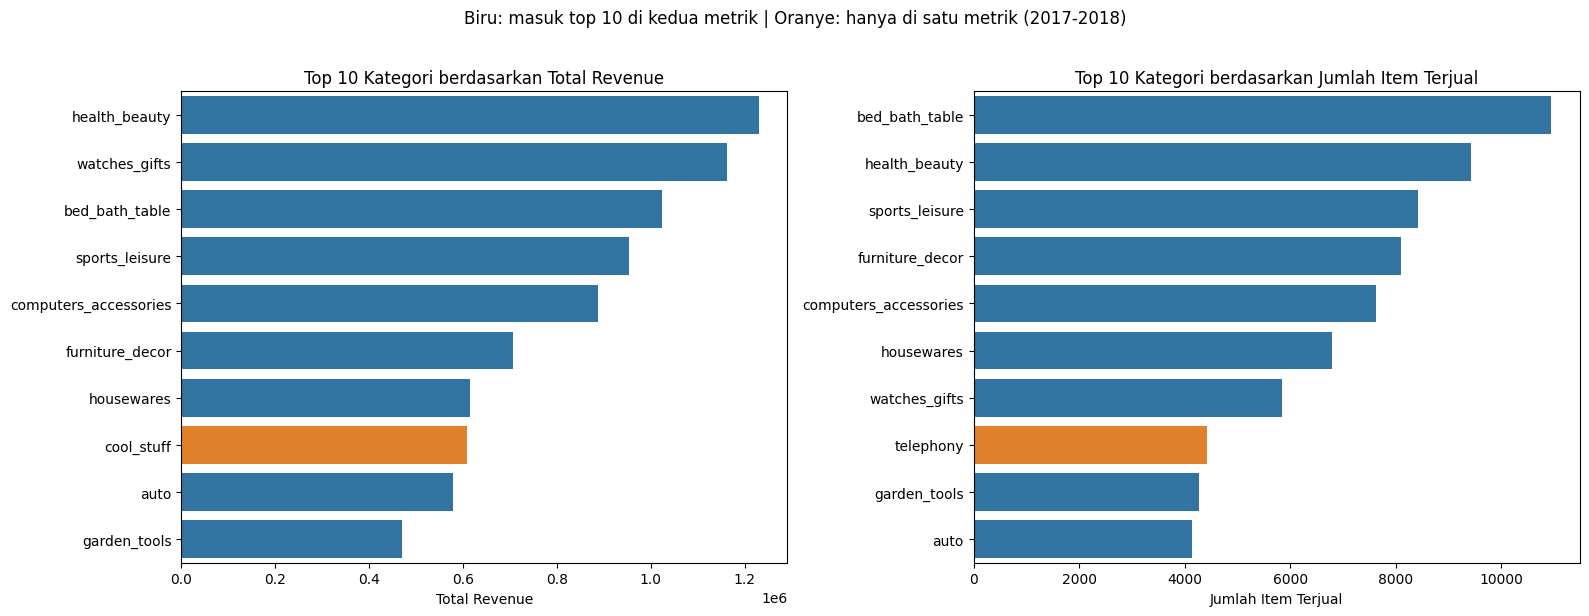

In [19]:
both = set(top_rev["product_category_name_english"]) & set(top_qty["product_category_name_english"])
warna = lambda df: ["#1f77b4" if k in both else "#ff7f0e" for k in df["product_category_name_english"]]

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(data=top_rev, x="revenue", y="product_category_name_english", palette=warna(top_rev), hue="product_category_name_english", legend=False, ax=ax[0])
ax[0].set_title("Top 10 Kategori berdasarkan Total Revenue")
ax[0].set_xlabel("Total Revenue"); ax[0].set_ylabel("")

sns.barplot(data=top_qty, x="items_sold", y="product_category_name_english", palette=warna(top_qty), hue="product_category_name_english", legend=False, ax=ax[1])
ax[1].set_title("Top 10 Kategori berdasarkan Jumlah Item Terjual")
ax[1].set_xlabel("Jumlah Item Terjual"); ax[1].set_ylabel("")

plt.suptitle("Biru: masuk top 10 di kedua metrik | Oranye: hanya di satu metrik (2017-2018)", y=1.02)
plt.tight_layout()
plt.show()

### Pertanyaan 2:

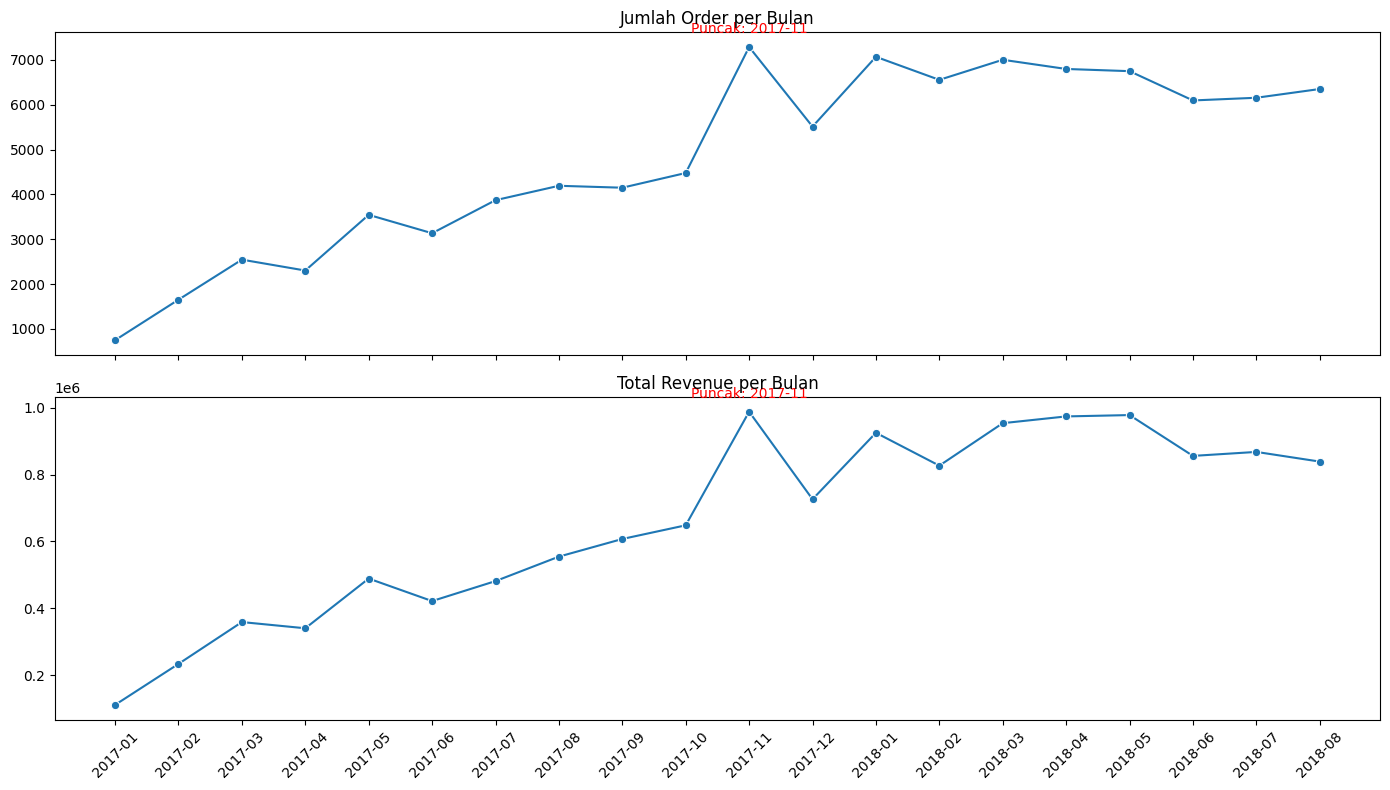

In [20]:
bulanan["bulan_str"] = bulanan["bulan"].astype(str)

fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for a, kolom, judul in [(ax[0], "jumlah_order", "Jumlah Order per Bulan"),
                        (ax[1], "total_revenue", "Total Revenue per Bulan")]:
    sns.lineplot(data=bulanan, x="bulan_str", y=kolom, marker="o", ax=a)
    puncak = bulanan.loc[bulanan[kolom].idxmax()]
    a.annotate(f"Puncak: {puncak['bulan_str']}", (puncak["bulan_str"], puncak[kolom]),
               textcoords="offset points", xytext=(0, 10), ha="center", color="red")
    a.set_title(judul); a.set_xlabel(""); a.set_ylabel("")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Pertanyaan 3:

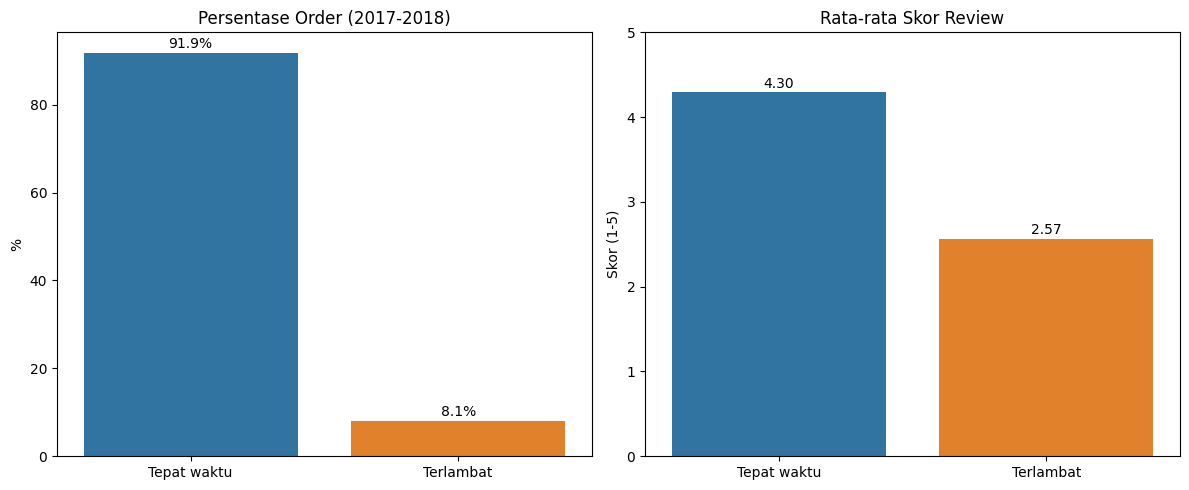

In [21]:
od_review["status_kirim"] = od_review["terlambat"].map({True: "Terlambat", False: "Tepat waktu"})
persen = od_review["status_kirim"].value_counts(normalize=True).mul(100)
rata = od_review.groupby("status_kirim")["review_score"].mean()

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sns.barplot(x=persen.index, y=persen.values, hue=persen.index, legend=False, ax=ax[0])
ax[0].set_title("Persentase Order (2017-2018)"); ax[0].set_ylabel("%"); ax[0].set_xlabel("")
for i, v in enumerate(persen.values):
    ax[0].text(i, v + 1, f"{v:.1f}%", ha="center")

sns.barplot(x=rata.index, y=rata.values, hue=rata.index, legend=False, ax=ax[1])
ax[1].set_title("Rata-rata Skor Review"); ax[1].set_ylabel("Skor (1-5)"); ax[1].set_xlabel("")
ax[1].set_ylim(0, 5)
for i, v in enumerate(rata.values):
    ax[1].text(i, v + 0.05, f"{v:.2f}", ha="center")

plt.tight_layout()
plt.show()

### Pertanyaan 4:

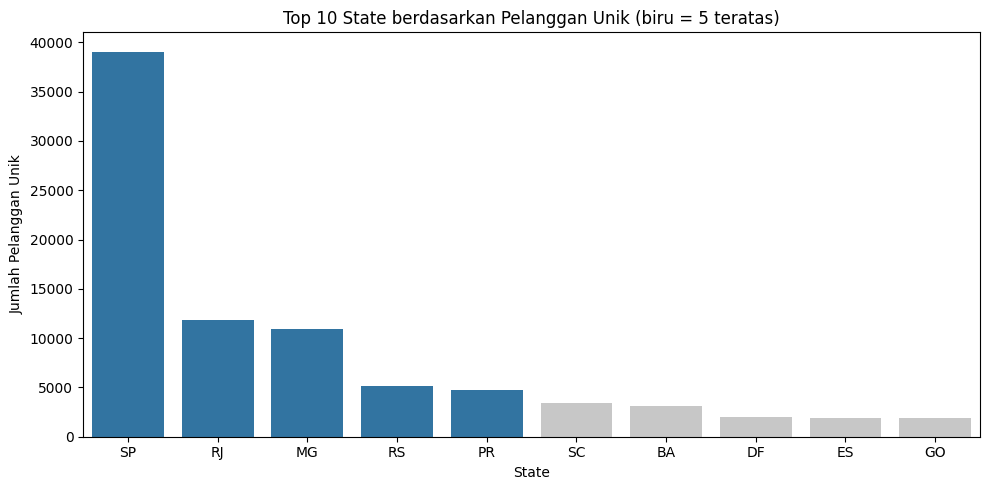

In [22]:
state10 = state.head(10).reset_index()
state10["warna"] = ["#1f77b4"] * 5 + ["#c7c7c7"] * 5

plt.figure(figsize=(10, 5))
sns.barplot(data=state10, x="customer_state", y="pelanggan_unik", palette=state10["warna"].tolist(),
            hue="customer_state", legend=False)
plt.title("Top 10 State berdasarkan Pelanggan Unik (biru = 5 teratas)")
plt.xlabel("State"); plt.ylabel("Jumlah Pelanggan Unik")
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Sembilan dari 10 kategori masuk top 10 di kedua metrik. `health_beauty` tertinggi di revenue, `bed_bath_table` tertinggi di jumlah item, sedangkan `cool_stuff` hanya unggul di revenue dan `telephony` hanya unggul di jumlah item.
- Jumlah order dan revenue naik sepanjang 2017 hingga puncak November 2017 (7.288 order, R$987.648), lalu relatif stabil di kisaran 6.000-7.100 order per bulan sepanjang 2018.
- Hanya 8,1% order yang terlambat, tetapi rata-rata skor review-nya (2,57) jauh lebih rendah dibanding order tepat waktu (4,30), selisih 1,73 poin.
- SP memiliki pelanggan unik terbanyak (39.058), dan lima state teratas (SP, RJ, MG, RS, PR) menyumbang 77,19% dari total order.

## Analisis Lanjutan (Opsional)

**Insight:** (Opsional)
- xxx
- xxx

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Top 10 kategori berdasarkan revenue dipimpin oleh `health_beauty`, sedangkan berdasarkan jumlah item terjual dipimpin oleh `bed_bath_table`. Kategori `health_beauty` hanya unggul di revenue (harga per item tinggi), sedangkan `bed_bath_table` hanya unggul di jumlah item (harga per item rendah).
- **Conclusion pertanyaan 2:** Jumlah order dan total revenue cenderung berfluktuasi selama Januari 2017 - Agustus 2018. Keduanya mencapai puncak pada November 2017.
- **Conclusion pertanyaan 3:** Selama periode 2017-2018, sebanyak 8,13% order delivered (7.822 dari 96.203) tiba melewati estimasi pengiriman. Rata-rata skor review order terlambat adalah 2,57, sedangkan order tepat waktu 4,30, sehingga selisihnya 1,73 poin. Keterlambatan pengiriman berkaitan dengan skor review yang jauh lebih rendah.
- **Conclusion pertanyaan 4:** State dengan pelanggan unik terbanyak adalah `SP` (39058 pelanggan). Lima state teratas (SP, RJ, MG, RS, PR) berkontribusi 77,19% terhadap total order.

**Rekomendasi Action Item:**
- Prioritaskan stok dan promosi untuk 9 kategori yang masuk top 10 di kedua metrik (health_beauty, watches_gifts, bed_bath_table, sports_leisure, computers_accessories, furniture_decor, housewares, garden_tools, dan auto), karena kategori ini konsisten kuat dari sisi revenue maupun volume. Untuk cool_stuff (hanya unggul di revenue, 3.711 item) fokuskan pada produk bernilai tinggi dengan stok terbatas, sedangkan untuk telephony (hanya unggul di jumlah item, 4.422 item) pertimbangkan strategi bundling atau cross-selling untuk menaikkan nilai per transaksi.
- Jadwalkan promosi besar dan siapkan kapasitas pengiriman (stok, gudang, dan mitra logistik) menjelang November, karena November 2017 menjadi puncak order dan revenue (7.288 order, R$987.648). Pertahankan kapasitas tinggi sepanjang 2018, karena volume bulanan stabil di atas 6.000 order. Kaji juga apakah lonjakan November berkaitan dengan momen promosi seperti Black Friday sebelum menjadikannya pola tahunan.
- Evaluasi layanan pengiriman untuk menekan keterlambatan (8,13%), misalnya dengan meninjau akurasi estimasi pengiriman dan rute atau mitra logistik yang sering terlambat, karena order terlambat memiliki skor review jauh lebih rendah.
- Fokuskan pemasaran dan distribusi di lima state teratas (SP, RJ, MG, RS, dan PR), terutama SP sebagai pasar terbesar, misalnya dengan menambah kapasitas gudang atau mitra logistik di wilayah tersebut. Karena 77,19% order terpusat di lima state, kaji juga potensi ekspansi di state berikutnya seperti SC dan BA, serta risiko ketergantungan pada satu wilayah.